In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

## Load in trajectory data

In [2]:
# load in traj data

import pandas as pd

dataset = 6
session = 'A1821-190910' #'A1824-190827'

data_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data'

positions = pd.read_csv(data_path / 'Tracking_data.csv')
positions.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']

positions

,timestamp,x,y,hd,pitch,roll
0,3044.968,-0.130861,0.100300,33.84858,-35.82468,0.539701
1,3044.978,-0.130832,0.100818,34.52600,-36.17565,1.159622
2,3044.988,-0.130896,0.101376,35.51010,-36.44134,1.384442
3,3044.998,-0.130989,0.101857,35.95627,-35.95127,2.098573
4,3045.008,-0.131249,0.102067,35.85831,-36.34102,2.746262
...,...,...,...,...,...,...
541520,11547.110,0.228479,0.181418,46.24308,44.69220,23.492130
541521,11547.120,0.228509,0.181343,46.41534,44.59696,23.677580
541522,11547.130,0.228535,0.181324,46.83366,44.50164,23.561010
541523,11547.140,0.228546,0.181349,47.37060,44.32819,23.070700


In [3]:
from scipy.io.matlab._mio5_params import mat_struct
from scipy.io import loadmat

# make sure to filter by epochs
def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

epochs = loadmat(data_path / 'BehavEpochs.mat', struct_as_record=False, squeeze_me=True)
if dataset == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])


In [4]:
# filter by epoch
positions = positions[['timestamp', 'x', 'y', 'hd']].to_numpy()
position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]

# normalize x/y positions to be positive
positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

len(positions)

270168

In [5]:
# Load in velocity data
velocity_data = []
vel_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data/Velocity.mat'
velocity_data = loadmat(vel_path, struct_as_record=False, squeeze_me=True)
        
velocity_data = extract_matlab_obj(velocity_data['vel'])
velocity_data = np.dstack((velocity_data['t'], velocity_data['data']))[0]
mask = (velocity_data[:, 0] > epoch_data['start']) & (velocity_data[:, 0] < epoch_data['stop'])
velocity_data = velocity_data[mask]

# velocity_data has shape (M, 3): [t, vx, vy] where speed = sqrt(vx**2 + vy**2)
vel_t   = velocity_data[:, 0]
vel_xy  = velocity_data[:, 1:3]
speed   = np.linalg.norm(vel_xy, axis=1)          # cm s-¹ I think this is unnecessary lol

# Interpolate speed at each position timestamp
pos_t   = positions[:, 0]
speed_at_pos = np.interp(pos_t, vel_t, speed, left=np.nan, right=np.nan)

speed_thresh = 5.0                               # cm s-¹
slow_mask = speed_at_pos < speed_thresh          # True where animal is < 5 cm/s

positions = positions[~slow_mask]


In [7]:
# calculate movement direction

def get_md_from_xy(positions, smoothing_window=140):
    def rolling_mean(positions):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(positions, kernel, mode='same')
        
    x = rolling_mean(positions[:, 1])
    y = rolling_mean(positions[:, 2])
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]

    direction = np.degrees(np.arctan2(dy, dx))
    direction = (direction + 360) % 360

    direction = np.concatenate([direction, [direction[-1]]])

    return direction

# get hd and md
hd = positions[:, 3]
hd = (hd + 360) % 360

md = get_md_from_xy(positions)


In [8]:
stimulus_type = "xy"

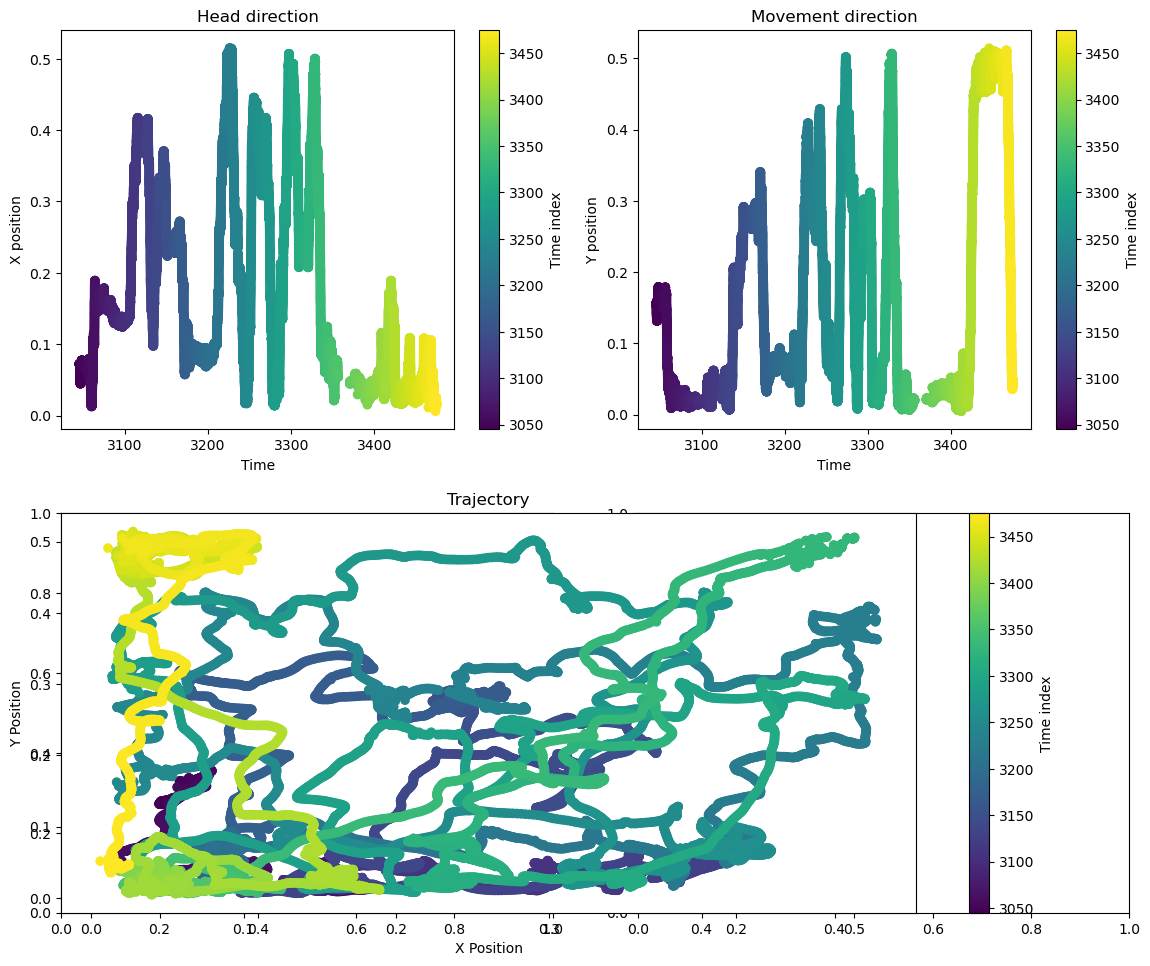

In [9]:
# display position trajectory, head direction, movement direction

if stimulus_type == 'xy':
    stimuli = (positions[:, 1], positions[:, 2])
    labels = ("X position", "Y position")
    limits = (0, max(np.max(stimuli[0]), np.max(stimuli[1])))
else:
    stimuli = (hd, md)
    labels = ("HD (degrees)", "MD (degrees)")
    limits = (0, 360)

time_window = 30000

timesteps = positions[:time_window, 0]

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10), gridspec_kw={'height_ratios': [1, 1]})

# Head direction plot (top left)
sc = axes[0, 0].scatter(timesteps, stimuli[0][:time_window], 
                        c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=axes[0, 0])
cbar.set_label("Time index")
axes[0, 0].set_xlabel("Time")
axes[0, 0].set_ylabel(labels[0])
axes[0, 0].set_title("Head direction")

# Movement direction plot (top right)
sc = axes[0, 1].scatter(timesteps, stimuli[1][:time_window], 
                        c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=axes[0, 1])
cbar.set_label("Time index")
axes[0, 1].set_xlabel("Time")
axes[0, 1].set_ylabel(labels[1])
axes[0, 1].set_title("Movement direction")

# Trajectory plot (bottom, spanning both columns)
ax_traj = fig.add_subplot(2, 1, 2)
sc = ax_traj.scatter(stimuli[0][:time_window], stimuli[1][:time_window], 
                     c=timesteps[:time_window], cmap='viridis')
cbar = fig.colorbar(sc, ax=ax_traj)
cbar.set_label("Time index")
ax_traj.set_xlabel("X Position")
ax_traj.set_ylabel("Y Position")
ax_traj.set_title("Trajectory")

# Adjust layout
plt.tight_layout()
plt.show()

## Create ideal model neuron

In [10]:
import numpy as np

def get_tuning_curve(
        stimuli,                 # (s1, s2) 1-D arrays of equal length
        limits,                  # (low, high) span for both dimensions
        *,
        stimulus_type='hd',      # 'hd'   ⇒ circular tuning; anything else ⇒ linear
        uniform=False,           # False ⇒ use the native trajectory in `stimuli`
        num_bins=17,
        min_rate=5,
        max_rate=35,
        seed=None
):
    rng = np.random.default_rng(seed)

    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0

    def stim_tuning(a, mu, sigma, amp):
        if stimulus_type == 'hd':            # circular difference
            delta = np.minimum(np.abs(a - mu), 360 - np.abs(a - mu))
        else:                                # linear
            delta = np.abs(a - mu)
        return amp * np.exp(-delta**2 / (2 * sigma**2))

    if stimulus_type == 'hd':
        mu, sigma = 200, 30
    else:
        mu, sigma = 0.2, 0.07

    lo, hi  = limits
    s_bins  = np.linspace(lo, hi, num_bins + 1)
    s1, s2 = stimuli

    if not uniform:
        rates  = np.exp(beta0 + stim_tuning(s1, mu, sigma, amplitude))  # need to be dividing for the time bins
        spike_counts = rng.poisson(rates)

    else:
        # fix all visits to the center of the bin
        bin_width = (hi - lo) / num_bins
        s1_idx = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
        s2_idx = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
        s1 = lo + (s1_idx + 0.5) * bin_width
        s2 = lo + (s2_idx + 0.5) * bin_width

        rates         = np.exp(beta0 + stim_tuning(s1, mu, sigma, amplitude))
        spike_counts  = rng.poisson(rates)

    rate_map, _, _ = np.histogram2d(s1, s2,
                                    bins=[s_bins, s_bins],
                                    weights=spike_counts)
    occ, _, _      = np.histogram2d(s1, s2, bins=[s_bins, s_bins])

    rate_map /= occ

    return (s1, s2), spike_counts, rate_map, occ, s_bins


# natural sampling
stim, spk, rmap, occ, s_bins = get_tuning_curve(
    stimuli,
    limits,
    stimulus_type='xy',      
    uniform=False,
    seed=0
)


# forced-uniform sampling
stim_u, spk_u, rmap_u, occ_u, s_bins = get_tuning_curve(
    stimuli,
    limits,
    stimulus_type='xy',
    uniform=True,
    seed=0
)


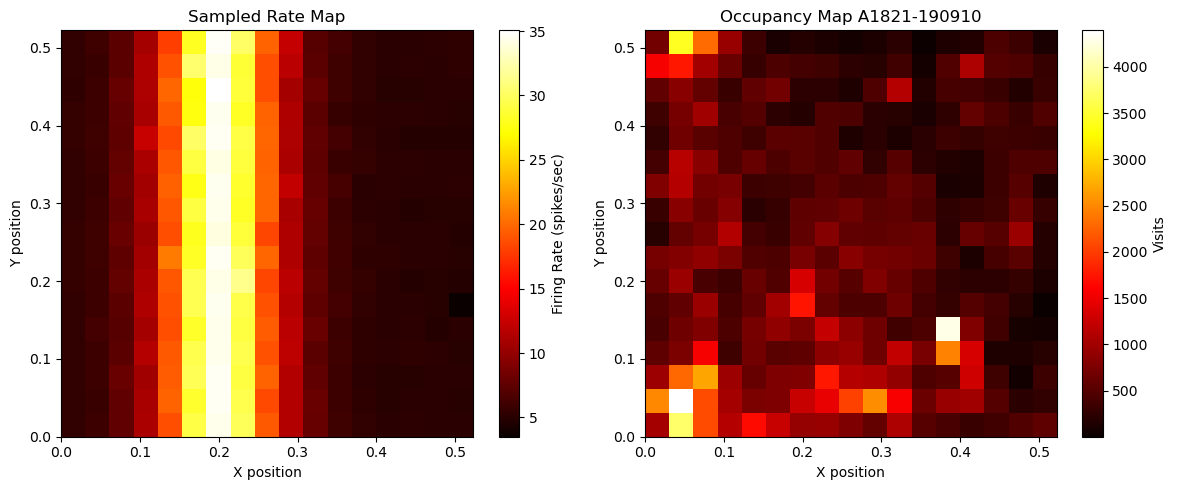

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(rmap.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
axs[0].set_xlabel(labels[0])
axs[0].set_ylabel(labels[1])
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(occ.T, origin='lower', aspect='auto',
                     extent=[s_bins[0], s_bins[-1], s_bins[0], s_bins[-1]],
                     cmap='hot')
axs[1].set_title(f"Occupancy Map {session}")
axs[1].set_xlabel(labels[0])
axs[1].set_ylabel(labels[1])
fig.colorbar(im2, ax=axs[1], label='Visits')

plt.tight_layout()
plt.show()

## Split the ideal neuron into folds

In [23]:
def get_splits(
        stim,                  # (s1,s2) from get_tuning_curve
        spike_counts,          # same length as s1/s2
        s_bins,                # bin edges returned by get_tuning_curve
        *,
        min_visits=200,
        seed=None,
        cap=False
):
    """
    Randomly halves the samples in each bin → train / test splits.

    Returns
    -------
    train_mean, test_mean : mean spike count in each bin (nan if <min_visits)
    train_occ,  test_occ  : visit counts assigned to each split
    """
    rng = np.random.default_rng(seed)
    num_bins = len(s_bins) - 1
    s1, s2 = stim

    train_mean = np.full((num_bins, num_bins), np.nan)
    test_mean  = np.full((num_bins, num_bins), np.nan)
    all_mean = np.full((num_bins, num_bins), np.nan)
    train_occ  = np.zeros((num_bins, num_bins), dtype=int)
    test_occ   = np.zeros((num_bins, num_bins), dtype=int)

    for i in range(num_bins):
        s1_lo, s1_hi = s_bins[i], s_bins[i + 1]
        mask1 = (s1 > s1_lo) & (s1 <= s1_hi)
        for j in range(num_bins):
            s2_lo, s2_hi = s_bins[j], s_bins[j + 1]
            idx = np.where(mask1 & (s2 > s2_lo) & (s2 <= s2_hi))[0]

            if len(idx) < min_visits:
                continue

            spikes = spike_counts[idx]
            rng.shuffle(spikes)
            if cap:
                spikes = spikes[:min_visits] 
            half   = len(spikes) // 2
            train, test = spikes[:half], spikes[half:]

            train_mean[i, j] = np.nan if len(train) == 0 else train.mean()
            test_mean[i,  j] = np.nan if len(test)  == 0 else test.mean()
            all_mean[i, j] = np.nan if len(spikes) == 0 else spikes.mean()
            train_occ[i, j]  = len(train)
            test_occ[i,  j]  = len(test)

    return all_mean, train_mean, test_mean, train_occ, test_occ



### Condition on one bin, then visualize

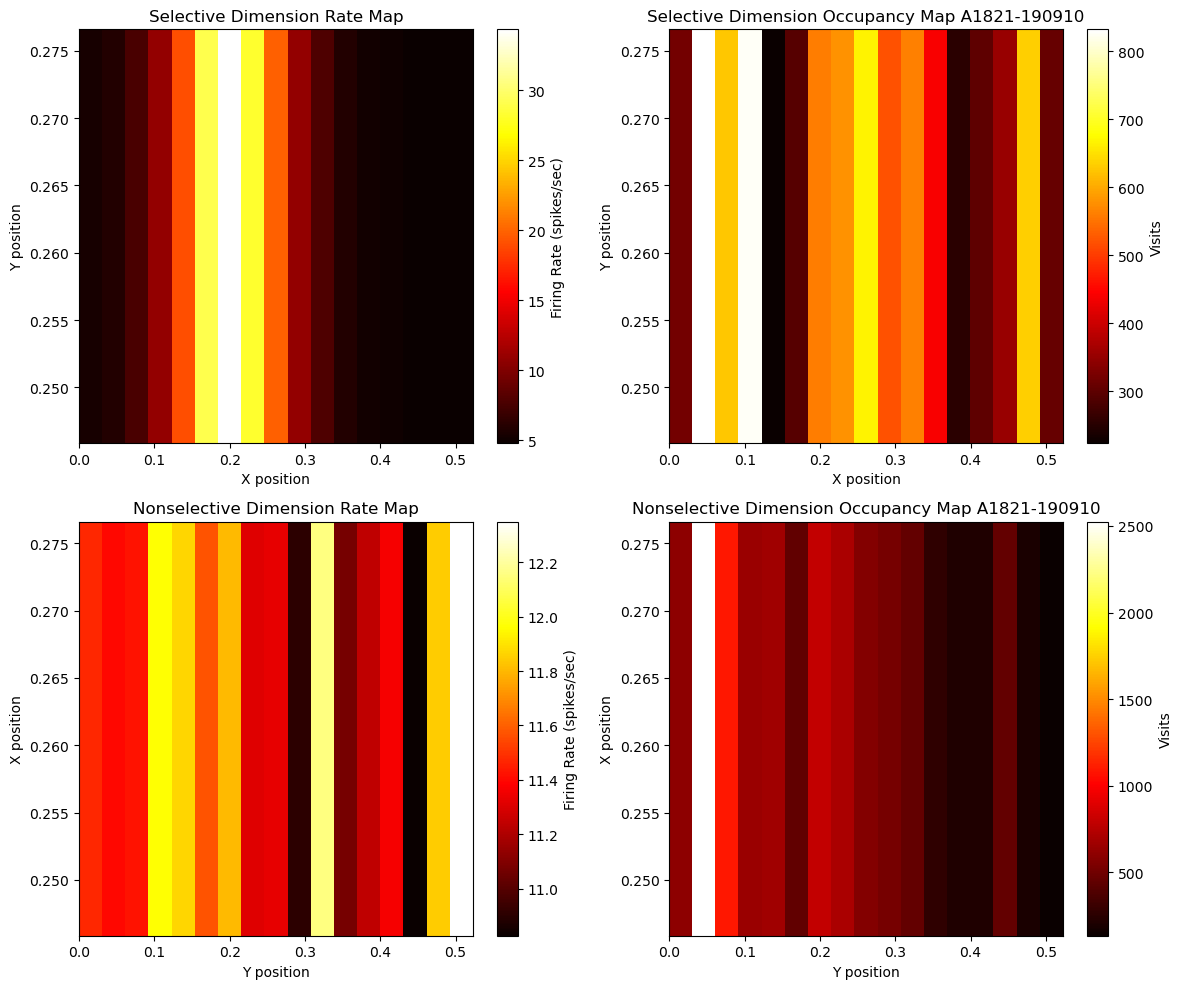

In [26]:
rmap, train_map, test_map, train_occ, test_occ = get_splits(stim, spk, s_bins, min_visits=2, seed=420, cap=False)

occc = train_occ + test_occ

fig, axs = plt.subplots(2, 2, figsize=(12, 10)) 

oned_idx = 9

# Selective dimension (row 0)
oned_rate_map_selective = rmap[:, oned_idx][np.newaxis, :] 
oned_occ_map_selective = occc[:, oned_idx][np.newaxis, :] 

# Nonselective dimension (row 1)
oned_rate_map_nonselective = rmap[oned_idx, :][np.newaxis, :] 
oned_occ_map_nonselective = occ[oned_idx, :][np.newaxis, :] 

# Selective Rate map
im1 = axs[0, 0].imshow(oned_rate_map_selective, origin='lower', aspect='auto',
                       extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                       cmap='hot')
axs[0, 0].set_title("Selective Dimension Rate Map")
axs[0, 0].set_xlabel(labels[0])
axs[0, 0].set_ylabel(labels[1])
fig.colorbar(im1, ax=axs[0, 0], label='Firing Rate (spikes/sec)')

# Selective Occupancy map
im2 = axs[0, 1].imshow(oned_occ_map_selective, origin='lower', aspect='auto',
                       extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                       cmap='hot')
axs[0, 1].set_title(f"Selective Dimension Occupancy Map {session}")
axs[0, 1].set_xlabel(labels[0])
axs[0, 1].set_ylabel(labels[1])
fig.colorbar(im2, ax=axs[0, 1], label='Visits')

# Nonselective Rate map
im3 = axs[1, 0].imshow(oned_rate_map_nonselective, origin='lower', aspect='auto',
                       extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                       cmap='hot')
axs[1, 0].set_title("Nonselective Dimension Rate Map")
axs[1, 0].set_xlabel(labels[1])  # flipped dimensions
axs[1, 0].set_ylabel(labels[0])
fig.colorbar(im3, ax=axs[1, 0], label='Firing Rate (spikes/sec)')

# Nonselective Occupancy map
im4 = axs[1, 1].imshow(oned_occ_map_nonselective, origin='lower', aspect='auto',
                       extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                       cmap='hot')
axs[1, 1].set_title(f"Nonselective Dimension Occupancy Map {session}")
axs[1, 1].set_xlabel(labels[1])
axs[1, 1].set_ylabel(labels[0])
fig.colorbar(im4, ax=axs[1, 1], label='Visits')

plt.tight_layout()
plt.show()


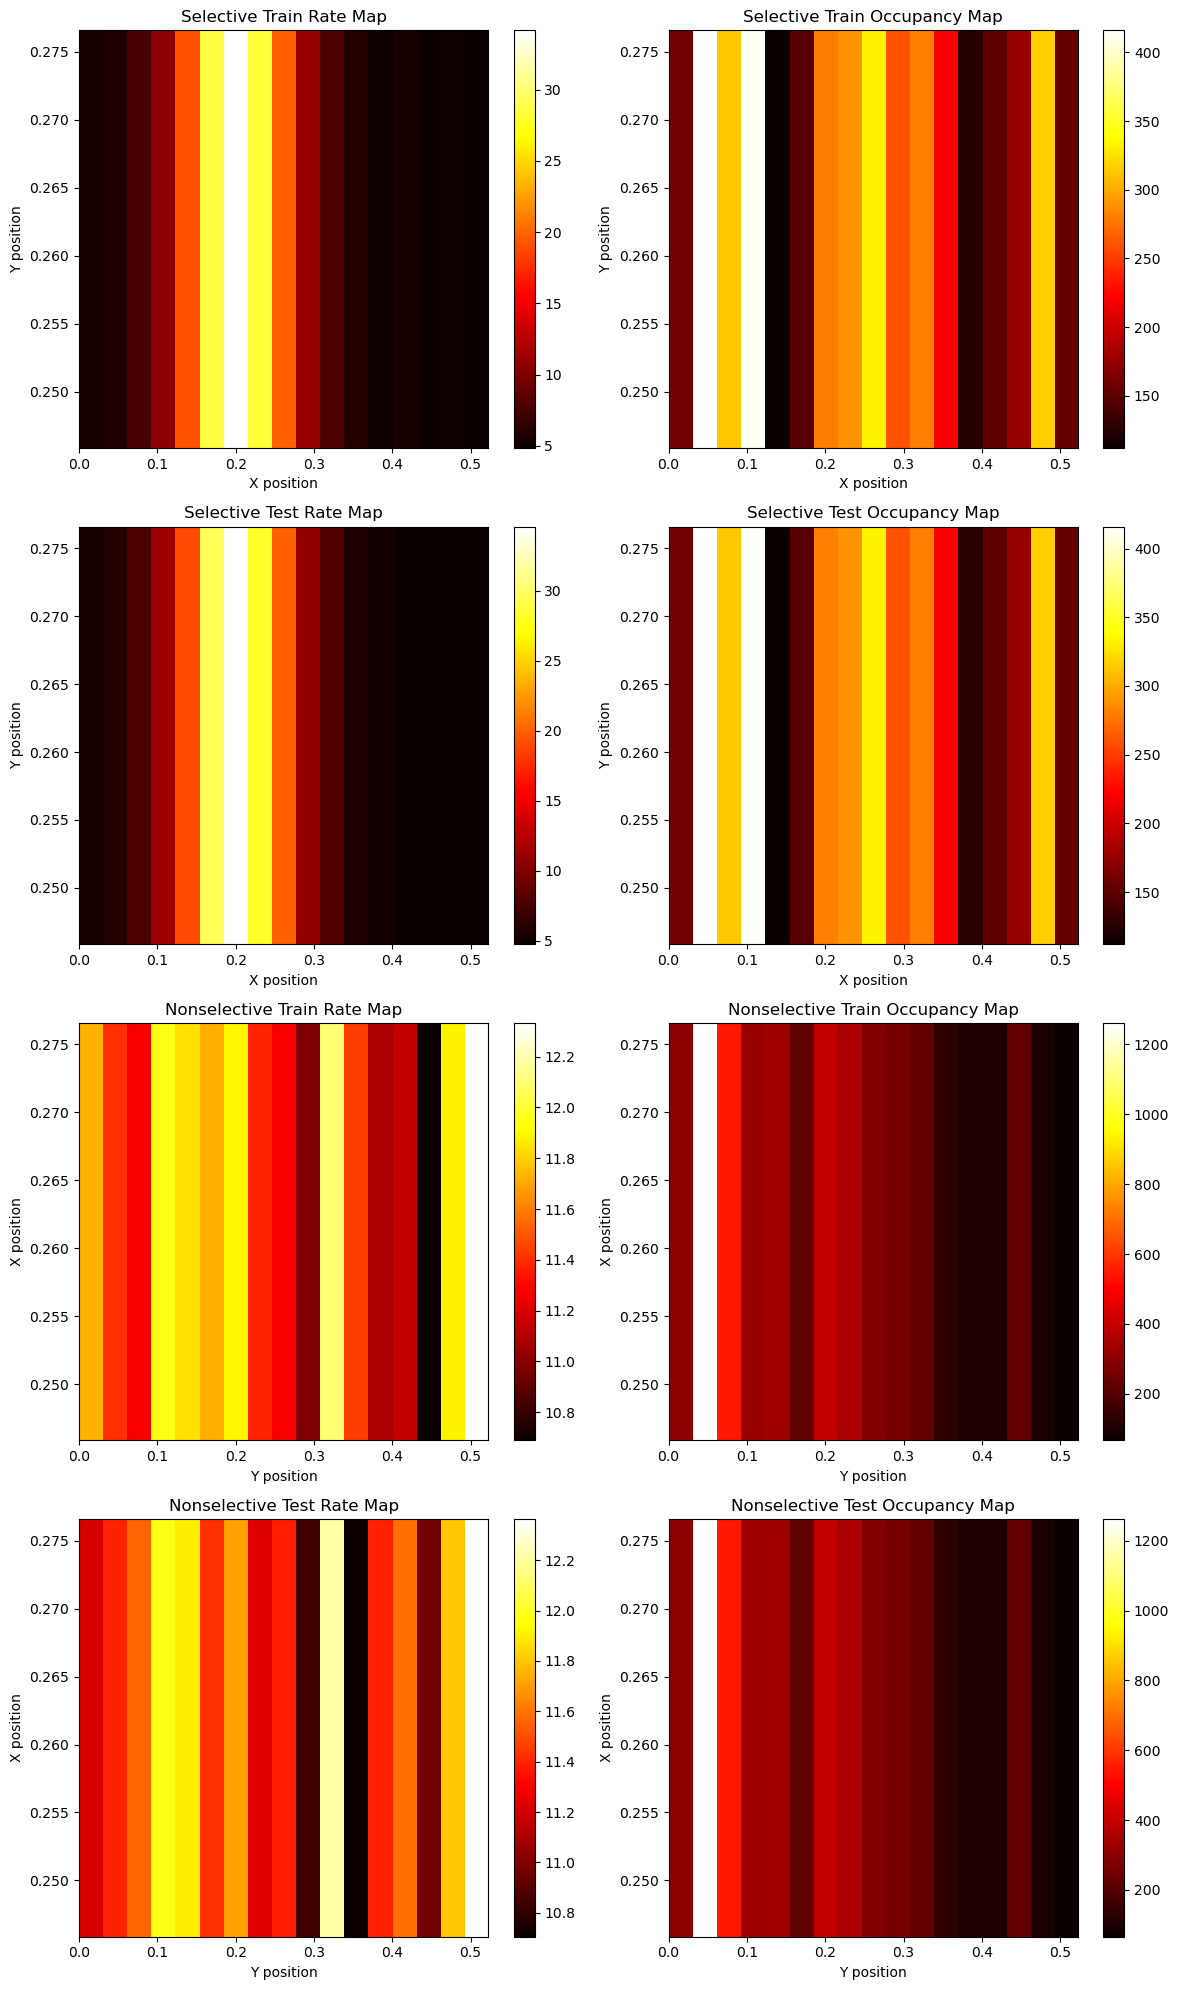

In [30]:
fig, axs = plt.subplots(4, 2, figsize=(12, 20))

# --- Selective dimension slices ---
oned_rate_map_selective_train = train_map[:, oned_idx][np.newaxis, :] 
oned_occ_map_selective_train = train_occ[:, oned_idx][np.newaxis, :] 
oned_rate_map_selective_test = test_map[:, oned_idx][np.newaxis, :] 
oned_occ_map_selective_test = test_occ[:, oned_idx][np.newaxis, :] 

# --- Nonselective dimension slices ---
oned_rate_map_train_1d = train_map[oned_idx, :][np.newaxis, :] 
oned_occ_map_train_1d = train_occ[oned_idx, :][np.newaxis, :] 
oned_rate_map_test_1d = test_map[oned_idx, :][np.newaxis, :] 
oned_occ_map_test_1d = test_occ[oned_idx, :][np.newaxis, :] 

# Row 1: Selective Train
im1 = axs[0, 0].imshow(oned_rate_map_selective_train, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[0, 0].set_title("Selective Train Rate Map")
axs[0, 0].set_xlabel(labels[0])
axs[0, 0].set_ylabel(labels[1])
fig.colorbar(im1, ax=axs[0, 0])

im2 = axs[0, 1].imshow(oned_occ_map_selective_train, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[0, 1].set_title("Selective Train Occupancy Map")
axs[0, 1].set_xlabel(labels[0])
axs[0, 1].set_ylabel(labels[1])
fig.colorbar(im2, ax=axs[0, 1])

# Row 2: Selective Test
im3 = axs[1, 0].imshow(oned_rate_map_selective_test, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[1, 0].set_title("Selective Test Rate Map")
axs[1, 0].set_xlabel(labels[0])
axs[1, 0].set_ylabel(labels[1])
fig.colorbar(im3, ax=axs[1, 0])

im4 = axs[1, 1].imshow(oned_occ_map_selective_test, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[1, 1].set_title("Selective Test Occupancy Map")
axs[1, 1].set_xlabel(labels[0])
axs[1, 1].set_ylabel(labels[1])
fig.colorbar(im4, ax=axs[1, 1])

# Row 3: Nonselective Train
im5 = axs[2, 0].imshow(oned_rate_map_train_1d, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[2, 0].set_title("Nonselective Train Rate Map")
axs[2, 0].set_xlabel(labels[1])
axs[2, 0].set_ylabel(labels[0])
fig.colorbar(im5, ax=axs[2, 0])

im6 = axs[2, 1].imshow(oned_occ_map_train_1d, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[2, 1].set_title("Nonselective Train Occupancy Map")
axs[2, 1].set_xlabel(labels[1])
axs[2, 1].set_ylabel(labels[0])
fig.colorbar(im6, ax=axs[2, 1])

# Row 4: Nonselective Test
im7 = axs[3, 0].imshow(oned_rate_map_test_1d, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[3, 0].set_title("Nonselective Test Rate Map")
axs[3, 0].set_xlabel(labels[1])
axs[3, 0].set_ylabel(labels[0])
fig.colorbar(im7, ax=axs[3, 0])

im8 = axs[3, 1].imshow(oned_occ_map_test_1d, origin='lower', aspect='auto',
                      extent=[s_bins[0], s_bins[-1], s_bins[oned_idx-1], s_bins[oned_idx]],
                      cmap='hot')
axs[3, 1].set_title("Nonselective Test Occupancy Map")
axs[3, 1].set_xlabel(labels[1])
axs[3, 1].set_ylabel(labels[0])
fig.colorbar(im8, ax=axs[3, 1])


plt.tight_layout()
plt.show()


## Run explained variance method on different conditions in 1D

In [32]:

def quantify_variance_1d(heatmap_test, heatmap_train, verbose=False):
    # heatmap_test and heatmap_train are average spikes/sec per behavioral bin
    
    test_mean = np.nanmean(heatmap_test)
    train_mean = np.nanmean(heatmap_train)

    n_bins = heatmap_test.shape[0]

    inter_var_test = np.nansum((heatmap_test - test_mean)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * (test_mean - train_mean)**2

    if verbose:
        print(f"sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"sum((test - train)^2)={intra_var_all:.4f}")
        print(f"n_bins * (test_mean - train_mean)^2={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


def quantify_variance(heatmap_test, heatmap_train, axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner.
    heatmaps are 2D, and are average spikes/sec across visits to each behavioral bin.
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    """

    test_mean = np.nanmean(heatmap_test, axis=axis)
    train_mean = np.nanmean(heatmap_train, axis=axis)

    # Expand along `axis` so we can subtract
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    n_bins = heatmap_test.shape[axis]

    # Now compute the variance terms with occupancy weighting
    inter_var_test = np.nansum((heatmap_test - test_mean_expanded)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean_expanded)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * np.nansum((test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"axis={axis} sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"axis={axis} sum((test - train)^2)={intra_var_all:.4f}")
        print(f"axis={axis} n_bins * sum((test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means

In [125]:
from scipy.stats import gaussian_kde

# type of interpolation intervention to try out
intervention = 'splits' # 'splits' | 'total'
normalize = False

# base params
num_bins = [5, 10, 15, 25, 35]
n_interp_bins = 40 # the finer-grained number of bins to do the second evaluation on

# sampling
curves = 15
splits = 15

explained_var = np.zeros((len(num_bins), curves, splits))

for nn, n_bins in enumerate(num_bins):
    oned_idx = n_bins // 2

    bin_edges = np.linspace(limits[0], limits[1], num=n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    interp_bin_edges = np.linspace(limits[0], limits[1], num=n_interp_bins + 1)
    interp_bin_centers = (interp_bin_edges[:-1] + interp_bin_edges[1:]) / 2
    
    for i in tqdm(range(curves)):
        stim, spikes, rate_map, occ, s_bins = get_tuning_curve(
            stimuli,              
            limits,
            stimulus_type='xy',    
            uniform=False,
            num_bins=n_bins,
            seed=i
        )

        for j in range(splits):
            rmap, train_map, test_map, _, _ = get_splits(
                stim, 
                spk, 
                s_bins,
                min_visits=4, 
                seed=j, 
                cap=False)

            train_1d = train_map[oned_idx, :]
            test_1d = test_map[oned_idx, :]

            if intervention == 'splits':
                # make both of the train/test splits interpolations with kde, then evaluate them at n_interp_bins centers
                train_interp = gaussian_kde(bin_centers, weights=train_1d)
                test_interp = gaussian_kde(bin_centers, weights=test_1d)
                train_1d = train_interp(interp_bin_centers)
                test_1d = test_interp(interp_bin_centers)
                
            elif intervention == 'total':
                # make an interpolation from the entire map, then get the variance per bin, and subtract from the dim calc
                s1, s2 = stim
                raw_points = np.stack([s1, s2], axis=1)
                total_interp = LinearNDInterpolator(raw_points, spikes, fill_value=np.nan)
                # TODO unfinished

            grand_mean = np.nanmean(rmap)
            total_ss = np.nansum((rmap - grand_mean)**2)
            
            explained_var[nn, i, j] = quantify_variance_1d(test_1d, train_1d, verbose=False)[0]# / total_ss
            explained_var[nn, i, j] /= total_ss if normalize else 1.
                
            # and sanity check that it's approximately the same as the 2d version
            twod_explained_var = quantify_variance(
                test_1d[np.newaxis, :], 
                train_1d[np.newaxis, :], 
                axis=1, 
                verbose=False
            )[0]
            
            twod_explained_var /= total_ss if normalize else 1.
            
            if not np.isclose(explained_var[nn, i, j], twod_explained_var, rtol=1e-02):
                print("1D and 2D methods are different")
                break



  0%|                                                                                            | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_667753/1546144030.py:55: RuntimeWarning: invalid value encountered in divide
  rate_map /= occ
100%|███████████████████████████████████████████████████████████████████████████████████| 15/15 [03:03<00:00, 12.23s/it]


In [70]:
occ[oned_idx]

array([ 72., 332., 483., 339., 278., 214., 235., 229., 261., 173., 139.,
       115.,  92., 153., 170., 279., 137., 106., 150., 183.,  98.,  70.,
        64., 222.,  66.,  21.,  91., 132.,  49.,  30.,  28.,  71.,  52.,
         7.,  28.])

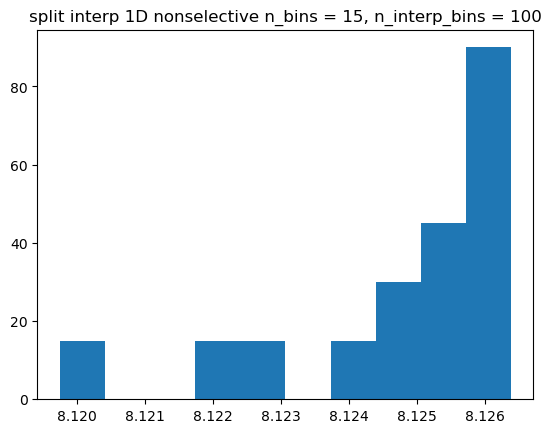

In [120]:
bin_idx = 2

plt.hist(explained_var[bin_idx].flatten())
plt.title(f'foldwise-interpolation 1D nonselective n_bins = {num_bins[bin_idx]}, n_interp_bins = {n_interp_bins}')
plt.show()

/tmp/ipykernel_667753/1415268955.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap     = cm.get_cmap('viridis', len(num_bins))          # or 'plasma', 'turbo' …


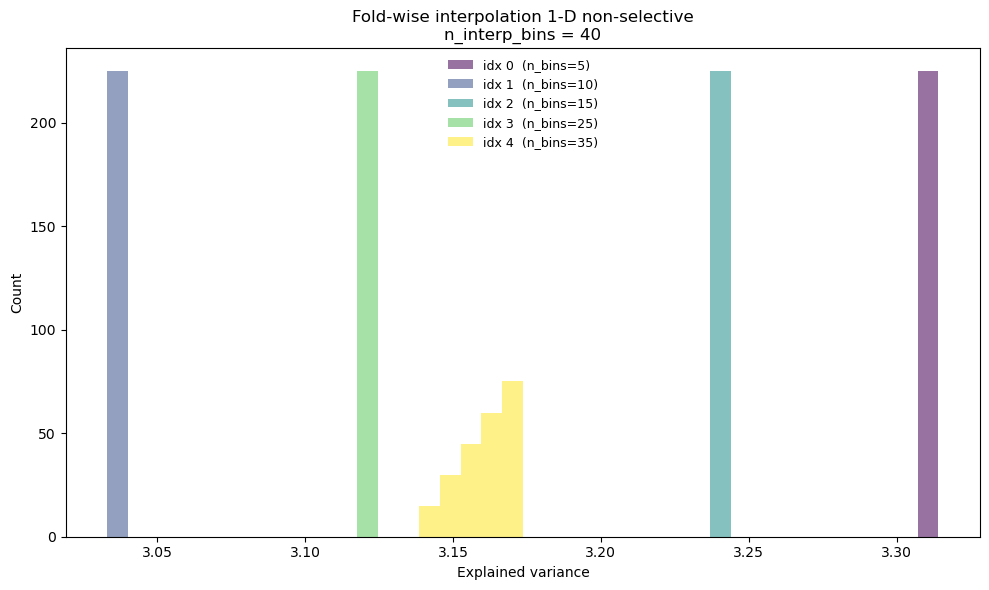

In [126]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# --- parameters you already have ----------
# explained_var   : list/array, shape = (n_idx, …)
# num_bins        : list/array, len = n_idx
# n_interp_bins   : scalar
# ------------------------------------------

# 1) Gather 1-D arrays to histogram
all_vals = [explained_var[i].ravel() for i in range(len(num_bins))]

# 2) Use a common set of histogram edges (here 40 uniform bins)
global_min = min(arr.min() for arr in all_vals)
global_max = max(arr.max() for arr in all_vals)
hist_edges  = np.linspace(global_min, global_max, 41)     # 40 equal-width bins

# 3) Build a colour palette that spans a colormap
cmap     = cm.get_cmap('viridis', len(num_bins))          # or 'plasma', 'turbo' …
colors   = [cmap(i) for i in range(len(num_bins))]

# 4) Plot
plt.figure(figsize=(10, 6))
for i, vals in enumerate(all_vals):
    plt.hist(
        vals,
        bins=hist_edges,
        alpha=0.55,                    # partly transparent so overlaps show through
        color=colors[i],
        label=f'idx {i}  (n_bins={num_bins[i]})',
        histtype='stepfilled',         # filled with an outline
        linewidth=0.8
    )

# 5) Cosmetics
plt.title(f'Fold-wise interpolation 1-D non-selective\n'
          f'n_interp_bins = {n_interp_bins}')
plt.xlabel('Explained variance')
plt.ylabel('Count')
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()
